# BNN logEI Online Experiment

Queue-backed BCLF optimization using the response-surrogate BNN acquisition backend.

This notebook is configured for the full online BNN baseline: `30` initial online cases, a first BNN fit for `800` epochs, then warm-start incremental learning for `20` epochs after each new online case.

In [2]:
from __future__ import annotations

from pathlib import Path
from datetime import datetime, timezone
import sys
import importlib
import json
import re

import numpy as np
import pandas as pd
import yaml

CWD = Path.cwd().resolve()
if (CWD / 'src').exists():
    REPO_ROOT = CWD
elif (CWD.parent / 'src').exists():
    REPO_ROOT = CWD.parent
else:
    raise RuntimeError(f'Cannot locate repo root from cwd={CWD}')

SRC = REPO_ROOT / 'src'
if str(SRC) in sys.path:
    sys.path.remove(str(SRC))
sys.path.insert(0, str(SRC))

importlib.invalidate_caches()
for mod in [
    m for m in list(sys.modules)
    if m == 'optimization' or m.startswith('optimization.') or m == 'simulation' or m.startswith('simulation.')
]:
    del sys.modules[mod]

from optimization import (
    BCLFOptimizationSpec,
    ContinuousCandidateSpace,
    DiscreteCandidateSpace,
    ExperimentRecorder,
    OptimizerBoTorch,
    BNNExpectedImprovementBackend,
    ServerQueueSimulator,
    ReplaySimulator,
    BCLFDataset,
)
from simulation.core import SimulationInput
from simulation.result_store import FilesystemResultStore, BandpassFilterNamingStrategy

In [3]:
# Core runtime switches
RUN_ONLINE = True  # Full online by default; set False to inspect/plot without queue jobs.
SIMULATOR_BACKEND = 'server'  # 'server' or 'replay'
RESUME_IF_CHECKPOINT = True
RESET_CHECKPOINT = False  # Keep False for long online campaigns; set True only for an intentional rerun.
CLEAR_QUEUE_ARTIFACTS_ON_RESET = True
DEBUG_VERBOSE = True
DEBUG_PRINT_EVERY = 1

# Campaign controls
SEEDS = [0, 1, 2, 3, 4]
N_INIT = 30
BUDGET = 50
POOL_SIZE = 1500
RETRAIN_EVERY = 1
METHOD_LABEL = 'bnn_response_qlogei'

# BNN baseline training schedule
BNN_INITIAL_EPOCHS = 800
BNN_UPDATE_EPOCHS = 20
BNN_DEVICE = "cuda"
BNN_BACKEND_CONFIG = {
    'hidden_dims': [256, 256, 256],
    'epochs': BNN_INITIAL_EPOCHS,
    'update_epochs': BNN_UPDATE_EPOCHS,
    'warm_start': True,
    'initial_train_size': N_INIT,
    'batch_size': 1024,
    'lr': 1e-3,
    'bayesian_loss_weight': 1e-4,
    'mc_samples': 64,
    'acquisition': 'qlogei',
}

# Paths
CONFIG_PATH = REPO_ROOT / 'configs' / 'filter_bnn_online_uaw_uaw.yaml'
REPLAY_DATASET_PATH = REPO_ROOT / 'data' / 'filter_bnn_online_uaw_uaw_dataset.pkl'
OUTPUT_DIR = REPO_ROOT / 'experiments' / 'bnn_online_general'
CACHE_DIR = REPO_ROOT / 'data' / 'bandpass_coupled_line_filter_export' / 'ext'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Queue + template settings
QUEUE_ROOT = REPO_ROOT / 'queue'
TEMPLATE_NAME = 'bclf_template_v1'
DESIGN_NAME = None
SETUP_NAME = None
SWEEP_NAME = None
UNIT_MAP = {
    'L': 'mm', 'L1': 'mm', 'L2': 'mm',
    'W': 'mm', 'W1': 'mm', 'W2': 'mm',
    'S1': 'mm', 'S2': 'mm',
}

print('repo root:', REPO_ROOT)
print('config:', CONFIG_PATH, 'exists=', CONFIG_PATH.exists())
print('output:', OUTPUT_DIR)
print('campaign_summary:', OUTPUT_DIR / 'campaign_summary.csv')
print('method:', METHOD_LABEL)
print('run_online:', RUN_ONLINE)
print('simulator_backend:', SIMULATOR_BACKEND)
print('seeds:', SEEDS)
print('target_trials:', N_INIT + BUDGET)
print('bnn_training_schedule:', {
    'initial_cases': N_INIT,
    'first_fit_epochs': BNN_INITIAL_EPOCHS,
    'incremental_update_epochs': BNN_UPDATE_EPOCHS,
    'retrain_every': RETRAIN_EVERY,
})

repo root: /home/zhanghf/projects/vector
config: /home/zhanghf/projects/vector/configs/filter_bnn_online_uaw_uaw.yaml exists= True
output: /home/zhanghf/projects/vector/experiments/bnn_online_general
campaign_summary: /home/zhanghf/projects/vector/experiments/bnn_online_general/campaign_summary.csv
method: bnn_response_qlogei
run_online: True
simulator_backend: server
seeds: [0, 1, 2, 3, 4]
target_trials: 80
bnn_training_schedule: {'initial_cases': 30, 'first_fit_epochs': 800, 'incremental_update_epochs': 20, 'retrain_every': 1}


In [4]:
if not CONFIG_PATH.exists():
    raise FileNotFoundError(f'CONFIG_PATH does not exist: {CONFIG_PATH}')

with CONFIG_PATH.open('r', encoding='utf-8') as f:
    cfg = yaml.safe_load(f)

variable_order = list(BCLFDataset.DEFAULT_FILTER_VARIABLE_ORDER)

reg_min = list(cfg['data']['regularization']['min'])
reg_max = list(cfg['data']['regularization']['max'])
if len(reg_min) == len(variable_order) + 1:
    reg_min = reg_min[:len(variable_order)]
    reg_max = reg_max[:len(variable_order)]
if len(reg_min) != len(variable_order):
    raise ValueError(f'Regularization dimension mismatch: len(min)={len(reg_min)} variable_order={len(variable_order)}')

variable_bounds = {
    name: (float(reg_min[i]), float(reg_max[i]))
    for i, name in enumerate(variable_order)
}

spec = BCLFOptimizationSpec(
    passband_ghz=(4.8, 5.4),
    lower_stopband_ghz=(3.6, 4.4),
    upper_stopband_ghz=(5.8, 8.7),
    min_passband_s21_db=-5.0,
    max_passband_s11_db=-7.0,
    max_stopband_s21_db=-15.0,
    s11_weight=0.5,
    stopband_weight=0.5,
)

display(pd.DataFrame({
    'variable': variable_order,
    'low': [variable_bounds[k][0] for k in variable_order],
    'high': [variable_bounds[k][1] for k in variable_order],
}))

,variable,low,high
0,L,7.70,7.90
1,L1,8.00,8.20
2,L2,7.80,8.00
3,W,0.90,1.10
4,W1,0.70,0.90
5,W2,0.90,1.10
6,S1,0.13,0.16
7,S2,0.55,0.60


In [5]:
def campaign_summary_path() -> Path:
    return OUTPUT_DIR / 'campaign_summary.csv'


def run_id_for_seed(seed: int) -> str:
    return f'bnn_online_general_seed{int(seed)}'


def checkpoint_for_seed(seed: int) -> Path:
    return OUTPUT_DIR / f'{run_id_for_seed(seed)}.checkpoint.json'


def target_trial_count() -> int:
    return int(N_INIT + BUDGET)


def _cleanup_queue_artifacts_for_run(queue_root: Path, run_id: str) -> dict[str, int]:
    """Remove stale queue artifacts matching run_id_itXXXX so a reset starts fresh."""
    removed = {'pending': 0, 'running': 0, 'done': 0, 'failed': 0}
    for state in ('pending', 'running', 'done', 'failed'):
        state_dir = queue_root / state
        if not state_dir.exists():
            continue
        suffix = '.result.json' if state in ('done', 'failed') else '.json'
        for artifact_path in state_dir.glob(f'{run_id}_it*{suffix}'):
            artifact_path.unlink(missing_ok=True)
            removed[state] += 1
    return removed


def _load_checkpoint_payload(seed: int) -> dict | None:
    checkpoint_path = checkpoint_for_seed(seed)
    if not checkpoint_path.exists():
        return None
    return json.loads(checkpoint_path.read_text(encoding='utf-8'))


def _checkpoint_history(seed: int) -> list[dict]:
    payload = _load_checkpoint_payload(seed)
    if payload is None:
        return []
    history = payload.get('history', [])
    return history if isinstance(history, list) else []


def effective_seed_for_rerun(seed: int) -> int:
    payload = _load_checkpoint_payload(seed)
    if payload is None or RESET_CHECKPOINT:
        return int(seed)
    checkpoint_seed = payload.get('seed')
    if checkpoint_seed is None:
        return int(seed)
    return int(checkpoint_seed)


def is_seed_completed(seed: int) -> bool:
    if RESET_CHECKPOINT:
        return False
    return len(_checkpoint_history(seed)) >= target_trial_count()


def _history_frame(seed: int, history: list[dict]) -> pd.DataFrame:
    hist = pd.DataFrame(history)
    if hist.empty:
        return hist
    hist = hist.copy()
    hist['seed'] = int(seed)
    if 'iteration' in hist:
        hist['iteration'] = pd.to_numeric(hist['iteration'], errors='coerce')
        hist = hist[np.isfinite(hist['iteration'])].copy()
        hist['iteration'] = hist['iteration'].astype(int)
        hist = hist.sort_values('iteration').reset_index(drop=True)
    return hist


def _first_feasible_iteration(history_df: pd.DataFrame) -> int | None:
    if history_df.empty or 'feasible' not in history_df or 'iteration' not in history_df:
        return None
    feasible_idx = history_df.index[history_df['feasible'] == True].tolist()  # noqa: E712
    return int(history_df.loc[feasible_idx[0], 'iteration']) if feasible_idx else None


def _best_objective_from_history(history_df: pd.DataFrame) -> float:
    if history_df.empty:
        return float('nan')
    if 'best_so_far' in history_df:
        best = pd.to_numeric(history_df['best_so_far'], errors='coerce')
        if np.isfinite(best).any():
            return float(np.nanmin(best))
    if 'objective' in history_df:
        objective = pd.to_numeric(history_df['objective'], errors='coerce')
        if np.isfinite(objective).any():
            return float(np.nanmin(objective))
    return float('nan')


def _cache_hit_ratio(history_df: pd.DataFrame) -> float:
    if history_df.empty or 'cache_hit' not in history_df:
        return float('nan')
    return float(history_df['cache_hit'].fillna(False).astype(bool).mean())


def _runtime_value(history_df: pd.DataFrame, column: str) -> float:
    if history_df.empty or column not in history_df:
        return float('nan')
    values = pd.to_numeric(history_df[column], errors='coerce')
    finite = values[np.isfinite(values)]
    return float(finite.iloc[-1]) if len(finite) else float('nan')


def _summary_row_for_seed(seed: int, status: str, history_df: pd.DataFrame) -> dict:
    run_id = run_id_for_seed(seed)
    return {
        'seed': int(seed),
        'run_id': run_id,
        'method': METHOD_LABEL,
        'status': status,
        'num_trials': int(len(history_df)),
        'best_objective': _best_objective_from_history(history_df),
        'first_feasible_iteration': _first_feasible_iteration(history_df),
        'cache_hit_ratio': _cache_hit_ratio(history_df),
        'runtime_engine_sec': _runtime_value(history_df, 't_engine_cum_sec'),
        'runtime_sim_sec': _runtime_value(history_df, 't_simulator_cum_sec'),
        'json': str(OUTPUT_DIR / f'{run_id}.json'),
        'csv': str(OUTPUT_DIR / f'{run_id}.csv'),
        'checkpoint': str(checkpoint_for_seed(seed)),
        'updated_at': datetime.now(timezone.utc).isoformat(),
    }


def load_campaign_summary(path: Path | None = None) -> pd.DataFrame:
    path = campaign_summary_path() if path is None else Path(path)
    if path.exists():
        df = pd.read_csv(path)
        if 'seed' in df.columns:
            df = df.sort_values('seed').reset_index(drop=True)
        return df
    return pd.DataFrame(columns=[
        'seed', 'run_id', 'method', 'status', 'num_trials', 'best_objective',
        'first_feasible_iteration', 'cache_hit_ratio', 'runtime_engine_sec',
        'runtime_sim_sec', 'json', 'csv', 'checkpoint', 'updated_at',
    ])


def upsert_campaign_row(row: dict, path: Path | None = None) -> pd.DataFrame:
    path = campaign_summary_path() if path is None else Path(path)
    df = load_campaign_summary(path)
    seed = int(row['seed'])
    if 'seed' in df.columns and (df['seed'] == seed).any():
        for key, value in row.items():
            df.loc[df['seed'] == seed, key] = value
    else:
        df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df = df.sort_values('seed').reset_index(drop=True)
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False)
    return df


def _progress_debug_callback(trial: dict, history: list[dict]) -> None:
    if not DEBUG_VERBOSE:
        return
    iteration = int(trial.get('iteration', -1))
    if DEBUG_PRINT_EVERY > 1 and iteration % int(DEBUG_PRINT_EVERY) != 0:
        return
    print(
        '[Optimizer]',
        f"iter={iteration:04d}",
        f"phase={trial.get('phase')}",
        f"obj={trial.get('objective')}",
        f"best={trial.get('best_so_far')}",
        f"status={trial.get('simulation_status')}",
        f"cache_hit={trial.get('cache_hit')}",
        f"job_id={trial.get('job_id')}",
    )
    sd = trial.get('selection_debug')
    if isinstance(sd, dict):
        mode = sd.get('mode')
        err = sd.get('select_error') or sd.get('fit_error')
        runtime = sd.get('bnn_runtime') if isinstance(sd.get('bnn_runtime'), dict) else {}
        print(
            '[SelectionDebug]',
            f"mode={mode}",
            f"error={err}",
            f"fit_mode={runtime.get('fit_mode')}",
            f"trained_epochs={runtime.get('trained_epochs')}",
        )


def _server_cached_response(simulator: ServerQueueSimulator, geometry: np.ndarray, *, case_id: str) -> tuple[np.ndarray, np.ndarray, np.ndarray, str] | None:
    values = np.asarray(geometry, dtype=float).reshape(-1)
    variables = {name: float(values[i]) for i, name in enumerate(simulator.variable_order)}
    quantized_variables = simulator._quantize_variables(variables)
    request = SimulationInput(
        case_id=case_id,
        variable_order=list(simulator.variable_order),
        variables=quantized_variables,
    )
    cached = simulator.result_store.lookup(request)
    if cached is None:
        return None
    freqs, s_params = simulator._load_touchstone(cached.touchstone_path)
    actual_geometry = np.array([quantized_variables[name] for name in simulator.variable_order], dtype=float)
    return freqs, s_params, actual_geometry, str(cached.touchstone_path)


def _rehydrate_history_responses(optimizer: OptimizerBoTorch, simulator: ServerQueueSimulator | ReplaySimulator) -> dict[str, int]:
    # Checkpoints intentionally skip response arrays; BNN resume needs them in memory for training.
    stats = {'existing': 0, 'rehydrated': 0, 'missing': 0, 'skipped': 0}
    for pos, row in enumerate(optimizer._history):
        if row.get('simulation_status') != 'done':
            stats['skipped'] += 1
            continue
        if row.get('_response_freqs') is not None and row.get('_response_s_params') is not None:
            stats['existing'] += 1
            continue
        geometry = row.get('geometry') or row.get('requested_geometry')
        if geometry is None:
            stats['missing'] += 1
            continue
        geometry_arr = np.asarray(geometry, dtype=float).reshape(-1)

        if isinstance(simulator, ReplaySimulator):
            sim_result = simulator.simulate(geometry_arr)
            if sim_result.status != 'done':
                stats['missing'] += 1
                continue
            freqs = sim_result.freqs
            s_params = sim_result.s_params
            actual_geometry = sim_result.actual_geometry if sim_result.actual_geometry is not None else geometry_arr
            touchstone_path = None
        elif isinstance(simulator, ServerQueueSimulator):
            case_id = str(row.get('case_id') or f'rehydrate_{pos:04d}')
            cached = _server_cached_response(simulator, geometry_arr, case_id=case_id)
            if cached is None:
                stats['missing'] += 1
                continue
            freqs, s_params, actual_geometry, touchstone_path = cached
        else:
            stats['missing'] += 1
            continue

        row['_response_freqs'] = np.asarray(freqs, dtype=float)
        row['_response_s_params'] = np.asarray(s_params, dtype=complex)
        row['geometry'] = np.asarray(actual_geometry, dtype=float).reshape(-1).tolist()
        row['geometry_normalized'] = np.asarray(
            optimizer.candidate_space.normalize(np.asarray(actual_geometry, dtype=float)),
            dtype=float,
        ).reshape(-1).tolist()
        if touchstone_path is not None:
            metadata = dict(row.get('simulation_metadata') or {})
            metadata['touchstone_path'] = touchstone_path
            row['simulation_metadata'] = metadata
        stats['rehydrated'] += 1
    print('[HistoryRehydrate]', stats)
    if stats['missing']:
        print('[HistoryRehydrate] Missing responses will make BNN fitting fall back until new in-memory responses are available.')
    return stats


def build_optimizer(seed: int) -> OptimizerBoTorch:
    run_id = run_id_for_seed(seed)
    checkpoint_path = checkpoint_for_seed(seed)
    optimizer_seed = effective_seed_for_rerun(seed)

    if RESET_CHECKPOINT:
        if checkpoint_path.exists():
            checkpoint_path.unlink()
        if CLEAR_QUEUE_ARTIFACTS_ON_RESET:
            removed = _cleanup_queue_artifacts_for_run(QUEUE_ROOT, run_id)
            print('[ResetCleanup]', f'run_id={run_id}', removed)

    if SIMULATOR_BACKEND == 'server':
        candidate_space = ContinuousCandidateSpace(
            variable_order=variable_order,
            variable_bounds=variable_bounds,
            pool_size=POOL_SIZE,
            seed=optimizer_seed,
            resolution=0.01,
        )
        result_store = FilesystemResultStore(
            root_dir=CACHE_DIR,
            naming_strategy=BandpassFilterNamingStrategy(),
            port_num=2,
        )
        simulator = ServerQueueSimulator(
            queue_root=str(QUEUE_ROOT),
            variable_order=variable_order,
            unit_map=UNIT_MAP,
            template_name=TEMPLATE_NAME,
            port_num=2,
            result_store=result_store,
            design_name=DESIGN_NAME,
            setup_name=SETUP_NAME,
            sweep_name=SWEEP_NAME,
            metrics_to_extract=['max_s11_db', 'min_s21_db'],
            run_id=run_id,
            mm_resolution=0.01,
            verbose=DEBUG_VERBOSE,
        )
    elif SIMULATOR_BACKEND == 'replay':
        freq_cfg = cfg['data']['freqs']
        freqs = np.arange(freq_cfg['min'], freq_cfg['max'], freq_cfg['step'], dtype=float)
        replay_dataset = BCLFDataset.from_pickle(REPLAY_DATASET_PATH, freqs=freqs)
        candidate_space = DiscreteCandidateSpace(
            variable_order=variable_order,
            candidate_geometries=replay_dataset.X_pool,
            match_atol=replay_dataset.match_atol,
            match_rtol=replay_dataset.match_rtol,
        )
        simulator = ReplaySimulator(dataset=replay_dataset)
    else:
        raise ValueError(f'Unsupported SIMULATOR_BACKEND={SIMULATOR_BACKEND}. Use server or replay.')

    optimizer = OptimizerBoTorch(
        candidate_space=candidate_space,
        simulator=simulator,
        optimization_spec=spec,
        recorder=ExperimentRecorder(output_dir=OUTPUT_DIR),
        budget=BUDGET,
        n_init=N_INIT,
        retrain_every=RETRAIN_EVERY,
        acquisition_backend=BNNExpectedImprovementBackend(BNN_BACKEND_CONFIG, device=BNN_DEVICE),
        seed=optimizer_seed,
        run_id=run_id,
        checkpoint_path=checkpoint_path,
        resume=(RESUME_IF_CHECKPOINT and checkpoint_path.exists()),
        progress_callback=_progress_debug_callback,
    )
    if RESUME_IF_CHECKPOINT and checkpoint_path.exists() and len(optimizer._history):
        _rehydrate_history_responses(optimizer, simulator)
    return optimizer

In [5]:
run_results = []
seed_history_frames = []
history_df = pd.DataFrame()
run_result = None
campaign_summary_df = pd.DataFrame()

if RUN_ONLINE:
    campaign_summary_df = load_campaign_summary()
    print('target_trials:', target_trial_count())
    print('campaign seeds:', SEEDS)

    for seed in SEEDS:
        seed = int(seed)
        checkpoint_path = checkpoint_for_seed(seed)
        checkpoint_history = _checkpoint_history(seed)
        checkpoint_df = _history_frame(seed, checkpoint_history)

        if is_seed_completed(seed):
            print(f'[Campaign] seed={seed} completed; skipping ({len(checkpoint_df)}/{target_trial_count()} trials).')
            campaign_summary_df = upsert_campaign_row(_summary_row_for_seed(seed, 'completed', checkpoint_df))
            seed_history_frames.append(checkpoint_df)
            history_df = checkpoint_df
            continue

        status_label = 'resuming' if checkpoint_path.exists() and len(checkpoint_df) else 'starting'
        optimizer_seed = effective_seed_for_rerun(seed)
        print(f'[Campaign] seed={seed} optimizer_seed={optimizer_seed} {status_label}; checkpoint={checkpoint_path}')
        optimizer = build_optimizer(seed)
        print('checkpoint_path:', optimizer.checkpoint_path, 'exists=', optimizer.checkpoint_path.exists())

        run_result = optimizer.run()
        run_results.append(run_result)
        history_df = pd.DataFrame(run_result.history).sort_values('iteration').reset_index(drop=True)
        history_df['seed'] = seed
        seed_history_frames.append(history_df)

        final_status = 'completed' if len(history_df) >= target_trial_count() else 'in_progress'
        campaign_summary_df = upsert_campaign_row(_summary_row_for_seed(seed, final_status, history_df))

        print('run_id:', run_result.run_id)
        print('best_objective:', run_result.state.best_objective)
        print('json:', run_result.recorder_output.json_path)
        print('csv:', run_result.recorder_output.csv_path)

    all_hist_df = (
        pd.concat([df for df in seed_history_frames if not df.empty], ignore_index=True)
        if any(not df.empty for df in seed_history_frames)
        else pd.DataFrame()
    )

    print('BNN logEI campaign summary:')
    display(campaign_summary_df)
    if not history_df.empty:
        display(history_df.tail(10))
else:
    all_hist_df = pd.DataFrame()
    print('RUN_ONLINE=False; set True after queue/template settings are ready.')

target_trials: 80
campaign seeds: [0, 1, 2, 3, 4]
[Campaign] seed=0 completed; skipping (80/80 trials).
[Campaign] seed=1 optimizer_seed=1 resuming; checkpoint=/home/zhanghf/projects/vector/experiments/bnn_online_general/bnn_online_general_seed1.checkpoint.json
[HistoryRehydrate] {'existing': 0, 'rehydrated': 50, 'missing': 0, 'skipped': 3}
checkpoint_path: /home/zhanghf/projects/vector/experiments/bnn_online_general/bnn_online_general_seed1.checkpoint.json exists= True


100%|█████████████████████████████████████████████| 1200/1200 [03:56<00:00,  5.07epoch/s, Epoch 1200/1200, Loss: 0.1582]


[ServerQueueSimulator] simulate call=1 run_id=bnn_online_general_seed1 geometry=[7.71, 8.19, 7.85, 0.95, 0.85, 0.95, 0.15, 0.59]
[ServerQueueSimulator] case_id=bnn_online_general_seed1_it0053 quantized_geometry=[7.71, 8.19, 7.85, 0.95, 0.85, 0.95, 0.15, 0.59] vars={'L': 7.71, 'L1': 8.19, 'L2': 7.85, 'W': 0.95, 'W1': 0.85, 'W2': 0.95, 'S1': 0.15, 'S2': 0.59}
[ServerQueueSimulator] enqueue: job_id=bnn_online_general_seed1_it0053 template=bclf_template_v1 output=bnn_online_general_seed1_it0053.s2p queue_root=/home/zhanghf/projects/vector/queue
[ServerQueueSimulator] wait result: case_id=bnn_online_general_seed1_it0053 status=done wait=1626.199s result_json=/home/zhanghf/projects/vector/queue/done/bnn_online_general_seed1_it0053.result.json


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [6]:
import matplotlib.pyplot as plt

if RUN_ONLINE and 'history_df' in globals() and not history_df.empty:
    plot_df = history_df.copy().sort_values('iteration')
    plot_df['best_so_far'] = pd.to_numeric(plot_df['best_so_far'], errors='coerce')
    finite_best = np.isfinite(plot_df['best_so_far'])

    if not finite_best.any():
        print('No finite best_so_far values yet.')
    else:
        fig, ax = plt.subplots(figsize=(8.5, 4.2))
        ax.plot(
            plot_df.loc[finite_best, 'iteration'],
            plot_df.loc[finite_best, 'best_so_far'],
            marker='o',
            lw=1.8,
            drawstyle='steps-post',
        )
        ax.axvline(N_INIT - 1, color='0.55', ls='--', lw=1.0, label='30 initial cases')
        ax.set_title('BNN logEI Best-so-far (Lower Is Better)')
        ax.set_xlabel('iteration')
        ax.set_ylabel('best objective so far')
        ax.grid(True, alpha=0.25)
        ax.legend(loc='best')
        plt.tight_layout()
else:
    print('No history available yet. Run the experiment cell first.')

No history available yet. Run the experiment cell first.


In [7]:
if RUN_ONLINE and 'history_df' in globals() and not history_df.empty:
    import matplotlib.pyplot as plt

    plot_df = history_df.copy().sort_values('iteration')
    plot_df['objective'] = pd.to_numeric(plot_df['objective'], errors='coerce')
    finite_obj = np.isfinite(plot_df['objective'])

    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    if finite_obj.any():
        ax.plot(plot_df.loc[finite_obj, 'iteration'], plot_df.loc[finite_obj, 'objective'], marker='o', lw=1.6)
    ax.axvline(N_INIT - 1, color='0.55', ls='--', lw=1.0, label='30 initial cases')
    ax.set_title('BNN logEI Objective by Iteration')
    ax.set_xlabel('iteration')
    ax.set_ylabel('objective (minimize)')
    ax.grid(True, alpha=0.25)
    ax.legend(loc='best')
    plt.tight_layout()

    if 'campaign_summary_df' in globals() and not campaign_summary_df.empty:
        cols = ['seed', 'run_id', 'method', 'status', 'best_objective', 'first_feasible_iteration', 'cache_hit_ratio', 'runtime_engine_sec', 'runtime_sim_sec', 'num_trials']
        print('Compact BNN logEI campaign metrics:')
        display(campaign_summary_df[cols])
else:
    print('No history available yet. Run the experiment cell first.')

No history available yet. Run the experiment cell first.


,iteration,obj_min,obj_max,obj_mean,n
0,0,46.493050,79.669474,63.081262,2
1,1,17.264189,64.236110,40.750150,2
2,2,38.214449,86.405734,62.310092,2
3,3,21.249523,30.353112,25.801318,2
4,4,30.145652,63.184710,46.665181,2
5,5,10.501635,51.607633,31.054634,2
6,6,17.289816,42.708086,29.998951,2
7,7,-2.214530,19.262875,8.524173,2
8,8,54.704456,61.540110,58.122283,2
9,9,-17.863279,24.040910,3.088815,2


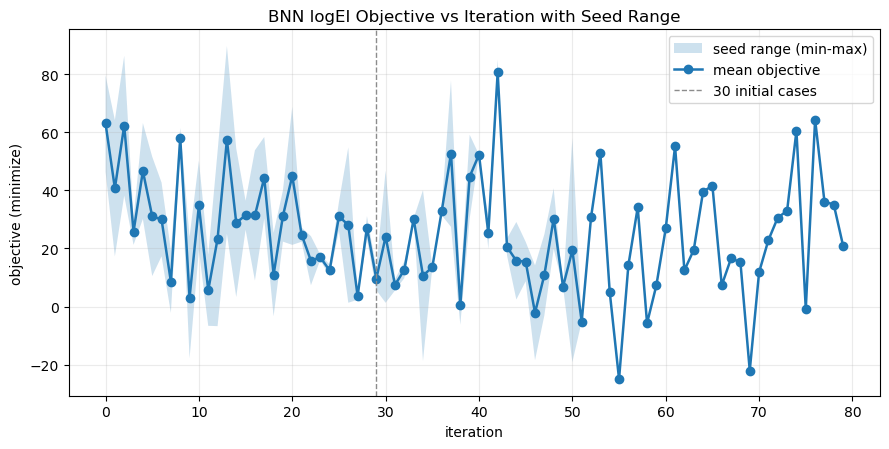

In [8]:
# Objective vs iteration with range band across configured seeds.
import matplotlib.pyplot as plt

if RUN_ONLINE:
    ckpt_paths = [checkpoint_for_seed(seed) for seed in SEEDS if checkpoint_for_seed(seed).exists()]
    if not ckpt_paths:
        print(f'No seed checkpoints found in {OUTPUT_DIR}')
    else:
        seed_pattern = re.compile(r'.*_seed(\d+)\.checkpoint\.json$')
        per_seed_histories: list[pd.DataFrame] = []

        for ckpt_path in ckpt_paths:
            payload = json.loads(ckpt_path.read_text())
            hist = pd.DataFrame(payload.get('history', []))
            if hist.empty or 'iteration' not in hist or 'objective' not in hist:
                continue

            seed_value = payload.get('seed')
            if seed_value is None:
                m = seed_pattern.match(ckpt_path.name)
                seed_value = int(m.group(1)) if m else None

            hist = hist.copy()
            hist['iteration'] = pd.to_numeric(hist['iteration'], errors='coerce')
            hist['objective'] = pd.to_numeric(hist['objective'], errors='coerce')
            hist = hist[np.isfinite(hist['iteration']) & np.isfinite(hist['objective'])]
            if hist.empty:
                continue

            hist['iteration'] = hist['iteration'].astype(int)
            hist['seed'] = seed_value
            per_seed_histories.append(hist[['seed', 'iteration', 'objective']])

        if not per_seed_histories:
            print('No valid objective/iteration history found in seed checkpoints.')
        else:
            all_hist_df = pd.concat(per_seed_histories, ignore_index=True)
            range_df = (
                all_hist_df
                .groupby('iteration', as_index=False)['objective']
                .agg(obj_min='min', obj_max='max', obj_mean='mean', n='count')
                .sort_values('iteration')
                .reset_index(drop=True)
            )

            fig, ax = plt.subplots(figsize=(9.0, 4.6))
            ax.fill_between(
                range_df['iteration'],
                range_df['obj_min'],
                range_df['obj_max'],
                alpha=0.22,
                label='seed range (min-max)',
            )
            ax.plot(
                range_df['iteration'],
                range_df['obj_mean'],
                lw=1.8,
                marker='o',
                label='mean objective',
            )
            ax.axvline(N_INIT - 1, color='0.55', ls='--', lw=1.0, label='30 initial cases')
            ax.set_title('BNN logEI Objective vs Iteration with Seed Range')
            ax.set_xlabel('iteration')
            ax.set_ylabel('objective (minimize)')
            ax.grid(True, alpha=0.25)
            ax.legend(loc='best')
            plt.tight_layout()

            display(range_df.head(20))
else:
    print('RUN_ONLINE is False; objective-range plot skipped.')

,iteration,best_min,best_max,best_mean,n
0,0,46.493050,79.669474,63.081262,2
1,1,17.264189,46.493050,31.878620,2
2,2,17.264189,38.214449,27.739319,2
3,3,17.264189,21.249523,19.256856,2
4,4,17.264189,21.249523,19.256856,2
5,5,10.501635,17.264189,13.882912,2
6,6,10.501635,17.264189,13.882912,2
7,7,-2.214530,10.501635,4.143553,2
8,8,-2.214530,10.501635,4.143553,2
9,9,-17.863279,10.501635,-3.680822,2


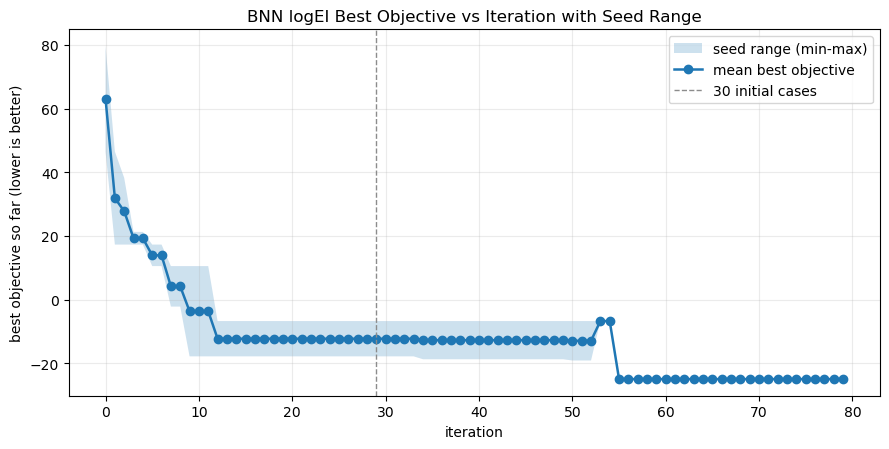

In [9]:
# Best objective (best-so-far) vs iteration with range band across configured seeds.
import matplotlib.pyplot as plt

if RUN_ONLINE:
    ckpt_paths = [checkpoint_for_seed(seed) for seed in SEEDS if checkpoint_for_seed(seed).exists()]
    if not ckpt_paths:
        print(f'No seed checkpoints found in {OUTPUT_DIR}')
    else:
        seed_pattern = re.compile(r'.*_seed(\d+)\.checkpoint\.json$')
        per_seed_best: list[pd.DataFrame] = []

        for ckpt_path in ckpt_paths:
            payload = json.loads(ckpt_path.read_text())
            hist = pd.DataFrame(payload.get('history', []))
            if hist.empty or 'iteration' not in hist:
                continue

            seed_value = payload.get('seed')
            if seed_value is None:
                m = seed_pattern.match(ckpt_path.name)
                seed_value = int(m.group(1)) if m else None

            hist = hist.copy()
            hist['iteration'] = pd.to_numeric(hist['iteration'], errors='coerce')

            if 'best_so_far' in hist:
                hist['best_so_far'] = pd.to_numeric(hist['best_so_far'], errors='coerce')
            elif 'objective' in hist:
                hist['objective'] = pd.to_numeric(hist['objective'], errors='coerce')
                hist['best_so_far'] = hist['objective'].cummin()
            else:
                continue

            hist = hist[np.isfinite(hist['iteration']) & np.isfinite(hist['best_so_far'])]
            if hist.empty:
                continue

            hist['iteration'] = hist['iteration'].astype(int)
            hist['seed'] = seed_value
            per_seed_best.append(hist[['seed', 'iteration', 'best_so_far']])

        if not per_seed_best:
            print('No valid best objective history found in seed checkpoints.')
        else:
            best_all_df = pd.concat(per_seed_best, ignore_index=True)
            best_range_df = (
                best_all_df
                .groupby('iteration', as_index=False)['best_so_far']
                .agg(best_min='min', best_max='max', best_mean='mean', n='count')
                .sort_values('iteration')
                .reset_index(drop=True)
            )

            fig, ax = plt.subplots(figsize=(9.0, 4.6))
            ax.fill_between(
                best_range_df['iteration'],
                best_range_df['best_min'],
                best_range_df['best_max'],
                alpha=0.22,
                label='seed range (min-max)',
            )
            ax.plot(
                best_range_df['iteration'],
                best_range_df['best_mean'],
                marker='o',
                lw=1.8,
                label='mean best objective',
            )
            ax.axvline(N_INIT - 1, color='0.55', ls='--', lw=1.0, label='30 initial cases')
            ax.set_title('BNN logEI Best Objective vs Iteration with Seed Range')
            ax.set_xlabel('iteration')
            ax.set_ylabel('best objective so far (lower is better)')
            ax.grid(True, alpha=0.25)
            ax.legend(loc='best')
            plt.tight_layout()

            display(best_range_df.head(20))
else:
    print('RUN_ONLINE is False; best-objective range plot skipped.')

,method,final_median,final_mean,final_best,final_worst,seeds
0,BNN logEI,-22.080659,-22.080659,-24.999434,-19.161885,2
1,LHS,-19.161885,-18.814976,-25.141275,-9.847343,5
2,BO logEI,-14.657114,-15.649376,-23.813877,-8.052391,5


,method,iteration,best_median,best_mean,best_min,best_max,n
220,LHS,60,-16.272256,-17.835083,-25.141275,-9.847343,5
221,LHS,61,-16.272256,-17.835083,-25.141275,-9.847343,5
222,LHS,62,-18.769620,-18.728211,-25.141275,-9.847343,5
223,LHS,63,-18.769620,-18.728211,-25.141275,-9.847343,5
224,LHS,64,-18.769620,-18.728211,-25.141275,-9.847343,5
225,LHS,65,-18.769620,-18.728211,-25.141275,-9.847343,5
226,LHS,66,-18.769620,-18.728211,-25.141275,-9.847343,5
227,LHS,67,-18.769620,-18.728211,-25.141275,-9.847343,5
228,LHS,68,-18.769620,-18.728211,-25.141275,-9.847343,5
229,LHS,69,-18.769620,-18.728211,-25.141275,-9.847343,5


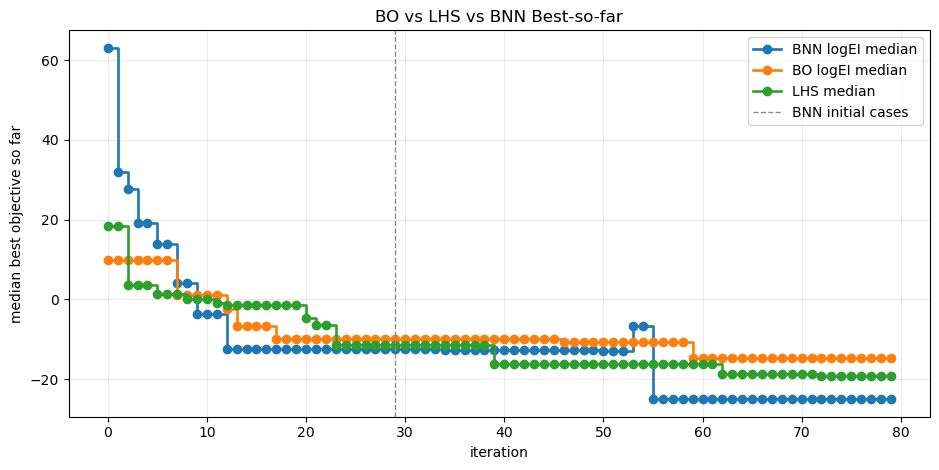

In [10]:
# Compare BO, LHS, and BNN best-so-far curves from checkpoints.
import matplotlib.pyplot as plt

METHOD_ROOTS = {
    'BO logEI': REPO_ROOT / 'experiments' / 'bo_online_general',
    'LHS': REPO_ROOT / 'experiments' / 'lhs_online_general',
    'BNN logEI': OUTPUT_DIR,
}


def _load_method_best_histories(method: str, root: Path) -> pd.DataFrame:
    rows: list[pd.DataFrame] = []
    if not root.exists():
        return pd.DataFrame(columns=['method', 'seed', 'iteration', 'best_so_far'])
    seed_pattern = re.compile(r'.*_seed(\d+)\.checkpoint\.json$')
    for ckpt_path in sorted(root.glob('*.checkpoint.json')):
        payload = json.loads(ckpt_path.read_text())
        hist = pd.DataFrame(payload.get('history', []))
        if hist.empty or 'iteration' not in hist:
            continue
        seed_value = payload.get('seed')
        if seed_value is None:
            m = seed_pattern.match(ckpt_path.name)
            seed_value = int(m.group(1)) if m else None
        hist = hist.copy()
        hist['iteration'] = pd.to_numeric(hist['iteration'], errors='coerce')
        if 'best_so_far' in hist:
            hist['best_so_far'] = pd.to_numeric(hist['best_so_far'], errors='coerce')
        elif 'objective' in hist:
            hist['objective'] = pd.to_numeric(hist['objective'], errors='coerce')
            hist['best_so_far'] = hist['objective'].cummin()
        else:
            continue
        hist = hist[np.isfinite(hist['iteration']) & np.isfinite(hist['best_so_far'])]
        if hist.empty:
            continue
        hist['iteration'] = hist['iteration'].astype(int)
        hist['seed'] = seed_value
        hist['method'] = method
        rows.append(hist[['method', 'seed', 'iteration', 'best_so_far']])
    if not rows:
        return pd.DataFrame(columns=['method', 'seed', 'iteration', 'best_so_far'])
    return pd.concat(rows, ignore_index=True)


comparison_histories = pd.concat(
    [_load_method_best_histories(method, root) for method, root in METHOD_ROOTS.items()],
    ignore_index=True,
)

if comparison_histories.empty:
    print('No BO/LHS/BNN checkpoints found for comparison yet.')
else:
    summary = (
        comparison_histories
        .groupby(['method', 'iteration'], as_index=False)['best_so_far']
        .agg(best_median='median', best_mean='mean', best_min='min', best_max='max', n='count')
        .sort_values(['method', 'iteration'])
        .reset_index(drop=True)
    )

    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    for method, method_df in summary.groupby('method', sort=False):
        method_df = method_df.sort_values('iteration')
        ax.plot(
            method_df['iteration'],
            method_df['best_median'],
            marker='o',
            lw=1.9,
            drawstyle='steps-post',
            label=f'{method} median',
        )
    ax.axvline(N_INIT - 1, color='0.55', ls='--', lw=1.0, label='BNN initial cases')
    ax.set_title('BO vs LHS vs BNN Best-so-far')
    ax.set_xlabel('iteration')
    ax.set_ylabel('median best objective so far')
    ax.grid(True, alpha=0.25)
    ax.legend(loc='best')
    plt.tight_layout()

    final_rows = (
        comparison_histories
        .sort_values('iteration')
        .groupby(['method', 'seed'], as_index=False)
        .tail(1)
        .groupby('method', as_index=False)['best_so_far']
        .agg(final_median='median', final_mean='mean', final_best='min', final_worst='max', seeds='count')
        .sort_values('final_median')
        .reset_index(drop=True)
    )
    display(final_rows)
    display(summary.tail(20))